# Counting hot days from CMIP6

This example examines how temperature variable and temporal resolution affect estimates of days above 95°F (35°C). Using GDPCIR data for four Peruvian provinces, it compares daily `tasmax`, daily `tavg`, and monthly `tavg`, and checks the consistency of annual mean temperatures across resolutions. The analysis covers 2000 and 2090 across three climate models.

In [1]:
import netCDF4
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cil_regionalization as cilreg
from cil_regionalization.bcsd_io import HOT_K, derive_daily

import data

pd.set_option("display.width", 160)
weights = {level: cilreg.WeightsArtifact.load(path) for level, path in data.WEIGHTS.items()}
for level, w in weights.items():
    ids = list(w.schema.id_fields)
    print(f"{level}: {w.frame[ids].drop_duplicates().shape[0]} units over "
          f"{w.frame[['cell_ix', 'cell_iy']].drop_duplicates().shape[0]} cells, grid {w.source_version}")

impact_region: 47 units over 503 cells, grid grid-0.25deg-center-[-180,180)
adm2: 28 units over 503 cells, grid grid-0.25deg-center-[-180,180)
adm1: 4 units over 503 cells, grid grid-0.25deg-center-[-180,180)


The example applies the Impact Map’s production weights to 503 grid cells.

## Daily data

Daily files contain maximum and minimum temperatures used to compare counts above 35°C (95°F) based on `tasmax` and daily mean temperature (`tavg`). December is excluded because DJF is outside the scope of this example.

In [2]:
def c_to_f(c):
    return c * 9.0 / 5.0 + 32.0


def daily_fields(model, experiment):
    with netCDF4.Dataset(data.daily_path(model, experiment)) as nc:
        tasmax = nc["tasmax"][:].filled(np.nan)
        tasmin = nc["tasmin"][:].filled(np.nan)
        cells = pd.DataFrame({"cell_ix": nc["cell_ix"][:], "cell_iy": nc["cell_iy"][:]})
    d = derive_daily(tasmax[:, None, :], tasmin[:, None, :], None)
    tavg = (tasmax.astype("float64") + tasmin.astype("float64")) / 2.0
    return cells.assign(
        days_tasmax=d.days_above_95F.ravel(),
        days_daily_tavg=(tavg > HOT_K).sum(axis=0).astype("float64"),
        mean_daily=c_to_f(d.tas_annual.ravel()),
    )


daily = {(m, e): daily_fields(m, e) for m in data.MODELS for e in data.YEARS}
daily["MIROC6", "ssp370"].describe().round(1)

,cell_ix,cell_iy,days_tasmax,days_daily_tavg,mean_daily
count,503.0,503.0,503.0,503.0,503.0
mean,426.2,317.5,41.3,0.0,74.3
std,12.9,11.1,38.9,0.2,11.9
min,394.0,298.0,0.0,0.0,39.4
25%,423.0,309.0,0.0,0.0,71.0
50%,429.0,316.0,48.0,0.0,80.8
75%,435.0,324.0,77.0,0.0,82.2
max,445.0,343.0,118.0,1.0,84.4


## Monthly data

Monthly files contain mean temperatures for each grid cell; cells outside the province are excluded. Hot-day counts are approximated by assigning all days in a month above 35°C to the total. Annual means are weighted by month length for comparison with daily estimates.

In [3]:
DAYS = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], dtype="float64")


def monthly_fields(model, experiment):
    cells, grid = cilreg.read_netcdf_grid(data.monthly_path(model, experiment), ["tavg"],
                                          lat="lat", lon="lon")
    assert grid == data.GRID
    wide = cells.pivot(index=["cell_ix", "cell_iy"], columns="month", values="tavg")
    tavg = wide[list(range(1, 13))].to_numpy(dtype="float64")
    return pd.DataFrame({
        "cell_ix": wide.index.get_level_values("cell_ix"),
        "cell_iy": wide.index.get_level_values("cell_iy"),
        "days_monthly_tavg": (tavg > HOT_K) @ DAYS,
        "mean_monthly": c_to_f(tavg @ DAYS / DAYS.sum() - 273.15),
    })


monthly = {(m, e): monthly_fields(m, e) for m in data.MODELS for e in data.YEARS}
monthly["MIROC6", "ssp370"].describe().round(1)

,cell_ix,cell_iy,days_monthly_tavg,mean_monthly
count,503.0,503.0,503.0,503.0
mean,426.2,317.5,0.0,74.3
std,12.9,11.1,0.0,11.9
min,394.0,298.0,0.0,39.4
25%,423.0,309.0,0.0,71.0
50%,429.0,316.0,0.0,80.8
75%,435.0,324.0,0.0,82.2
max,445.0,343.0,0.0,84.4


## Aggregating to three levels

We use `apply_weights` to aggregate each field with population weights at the impact-region, ADM2, and ADM1 levels. The run stops if the data and weights don’t contain the same cells or a cell has no weight.

In [4]:
POLICIES = cilreg.SourceUnitPolicies(on_unmatched="error", on_zero_weight="error",
                                     on_absent_from_data="error")

frames = []
for (model, experiment), d in daily.items():
    both = d.merge(monthly[model, experiment], on=["cell_ix", "cell_iy"], validate="one_to_one")
    assert len(both) == len(d) == len(monthly[model, experiment])
    frames.append(both.melt(id_vars=["cell_ix", "cell_iy"], var_name="field")
                  .assign(model=model, year=data.YEARS[experiment]))
cells_long = pd.concat(frames, ignore_index=True)

out = {level: cilreg.apply_weights(w, cells_long, kind="intensive", weight="pop",
                                   data_version=data.GRID, policies=POLICIES).frame
       for level, w in weights.items()}
{level: len(f) for level, f in out.items()}

{'impact_region': 1410, 'adm2': 840, 'adm1': 120}

In [5]:
COLUMNS = {
    "days_tasmax": "days, daily tasmax",
    "days_daily_tavg": "days, daily tavg",
    "days_monthly_tavg": "days, monthly tavg",
    "mean_daily": "annual mean F, daily",
    "mean_monthly": "annual mean F, monthly",
}
adm1 = out["adm1"].assign(province=lambda f: f["ID_1"].map(data.PROVINCES))
table = (adm1.pivot(index=["province", "year", "model"], columns="field", values="value")
         [list(COLUMNS)].rename(columns=COLUMNS))
print(f"largest gap between the two annual means: "
      f"{(table[COLUMNS['mean_daily']] - table[COLUMNS['mean_monthly']]).abs().max():.1e} F")
table.round({c: 1 for c in COLUMNS.values()}).round({COLUMNS["mean_daily"]: 2, COLUMNS["mean_monthly"]: 2})

largest gap between the two annual means: 1.2e-05 F


field                           days, daily tasmax  days, daily tavg  days, monthly tavg  annual mean F, daily  annual mean F, monthly
province      year model                                                                                                              
Cusco         2000 FGOALS-g3                   0.0               0.0                 0.0                  48.7                    48.7
                   MIROC6                      0.0               0.0                 0.0                  48.1                    48.1
                   UKESM1-0-LL                 0.0               0.0                 0.0                  47.8                    47.8
              2090 FGOALS-g3                   0.1               0.0                 0.0                  53.9                    53.9
                   MIROC6                      0.5               0.0                 0.0                  52.3                    52.3
                   UKESM1-0-LL                 2.9               0.2                 0.1                  58.5                    58.5
Madre de Dios 2000 FGOALS-g3                   2.8               0.0                 0.0                  77.1                    77.1
                   MIROC6                      0.3               0.0                 0.0                  76.8                    76.8
                   UKESM1-0-LL                 1.1               0.0                 0.0                  76.3                    76.3
              2090 FGOALS-g3                  53.3               0.0                 0.0                  82.7                    82.7
                   MIROC6                     70.3               0.0                 0.0                  81.1                    81.1
                   UKESM1-0-LL               286.4             126.2               130.3                  91.9                    91.9
Piura         2000 FGOALS-g3                   0.9               0.0                 0.0                  73.2                    73.2
                   MIROC6                      2.0               0.0                 0.0                  73.0                    73.0
                   UKESM1-0-LL                 0.5               0.0                 0.0                  72.9                    72.9
              2090 FGOALS-g3                  37.7               0.0                 0.0                  78.5                    78.5
                   MIROC6                      2.3               0.0                 0.0                  75.6                    75.6
                   UKESM1-0-LL               112.2               0.7                 0.0                  82.9                    82.9
Ucayali       2000 FGOALS-g3                   3.3               0.0                 0.0                  79.6                    79.6
                   MIROC6                      2.4               0.0                 0.0                  79.2                    79.2
                   UKESM1-0-LL                 2.2               0.0                 0.0                  78.9                    78.9
              2090 FGOALS-g3                  56.8               0.0                 0.0                  84.3                    84.3
                   MIROC6                     75.2               0.0                 0.0                  82.9                    82.9
                   UKESM1-0-LL               322.4             160.4               171.6                  93.7                    93.7

## Hot-day counts

In Madre de Dios, UKESM1-0-LL gives 286 days above 35°C in 2090 using daily `tasmax`, compared with 126 using daily `tavg` and 130 using monthly `tavg`. The monthly estimate is slightly closer to the `tasmax` count, but assigns entire months above the threshold; these measures are not interchangeable.

## Spatial aggregation

For MIROC6 in 2090, `tasmax` counts range from 0–99 days across impact regions, 0–97 at ADM2, and 1–75 at ADM1. Averaging over larger areas reduces spatial variation.

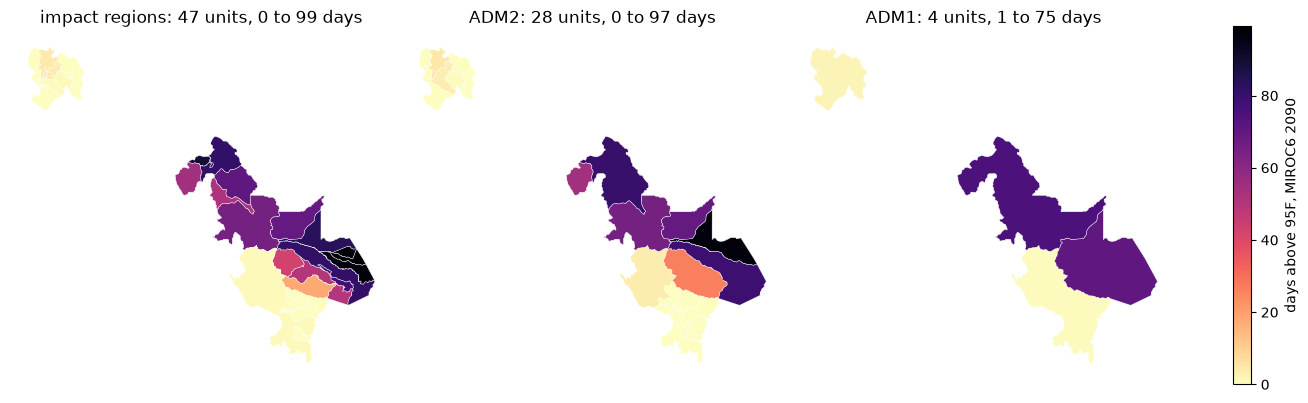

In [6]:
MODEL, YEAR = "MIROC6", data.YEARS["ssp370"]
keys = {"impact_region": ["hierid"], "adm2": ["ISO", "ID_1", "ID_2"], "adm1": ["ISO", "ID_1"]}
titles = {"impact_region": "impact regions", "adm2": "ADM2", "adm1": "ADM1"}

values = {level: f[(f["field"] == "days_tasmax") & (f["model"] == MODEL) & (f["year"] == YEAR)]
          for level, f in out.items()}
vmax = max(v["value"].max() for v in values.values())
fig, axes = plt.subplots(1, 3, figsize=(13, 5.2), constrained_layout=True)
for ax, level in zip(axes, keys):
    shapes = gpd.read_parquet(data.OUTLINES[level]).merge(
        values[level], on=keys[level], how="left", validate="one_to_one")
    assert shapes["value"].notna().all()
    shapes.plot(column="value", ax=ax, cmap="magma_r", vmin=0, vmax=vmax,
                edgecolor="white", linewidth=0.3)
    lo, hi = shapes["value"].min(), shapes["value"].max()
    ax.set_title(f"{titles[level]}: {len(shapes)} units, {lo:.0f} to {hi:.0f} days")
    ax.set_axis_off()
fig.colorbar(plt.cm.ScalarMappable(cmap="magma_r", norm=plt.Normalize(0, vmax)),
             ax=axes, shrink=0.7, label=f"days above 95F, {MODEL} {YEAR}")
plt.show()

## CMIP6 ensemble spread

The climate tables report provincial counts of days above 95°F (35°C) for 2080–2099 under SSP3-7.0 across 20 equally weighted models. MIROC6 projects approximately 3 days for Piura and 136 for Ucayali, while CanESM5 produces the highest counts.

In [7]:
summary = pd.read_csv(data.SUMMARY)
wide = (summary.pivot(index="model", columns="province", values="days_above_95F")
        [list(data.PROVINCES.values())].sort_values("Ucayali"))
wide["in the daily files"] = np.where(wide.index.isin(list(data.MODELS)), "yes", "")
wide.round(1)

province,Ucayali,Madre de Dios,Piura,Cusco,in the daily files
model,,,,,
FGOALS-g3,57.6,53.7,24.1,0.2,yes
INM-CM4-8,68.0,53.4,29.9,0.2,
INM-CM5-0,70.8,51.8,31.0,0.2,
NorESM2-LM,112.1,78.6,33.5,0.4,
EC-Earth3-Veg-LR,114.8,90.2,44.2,0.6,
MIROC-ES2L,115.4,73.2,33.2,0.4,
EC-Earth3,119.0,95.9,43.0,0.8,
EC-Earth3-Veg,120.7,99.7,43.4,0.8,
MPI-ESM1-2-LR,128.8,84.9,33.0,0.5,


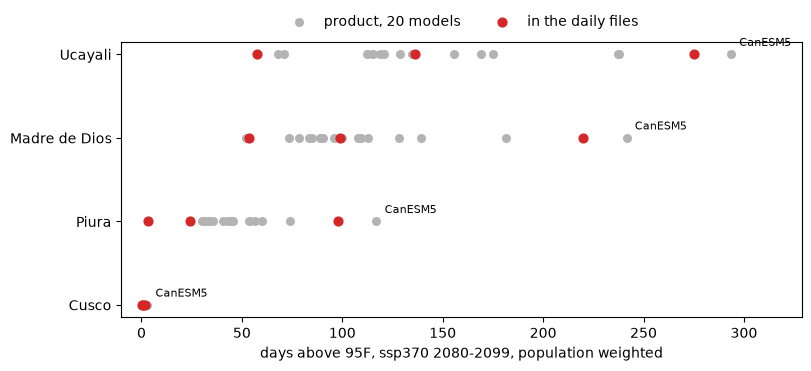

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
for y, province in enumerate(data.PROVINCES.values()):
    v = wide[province]
    ax.scatter(v, np.full(len(v), y), color="0.7", s=30, label="product, 20 models" if y == 0 else None)
    mine = v[wide["in the daily files"] == "yes"]
    ax.scatter(mine, np.full(len(mine), y), color="C3", s=40,
               label="in the daily files" if y == 0 else None)
    ax.annotate("CanESM5", (v["CanESM5"], y), xytext=(6, 6), textcoords="offset points",
                ha="left", fontsize=8)
ax.set_yticks(range(len(data.PROVINCES)), list(data.PROVINCES.values()))
ax.set_xlim(-10, wide[list(data.PROVINCES.values())].to_numpy().max() * 1.12)
ax.invert_yaxis()
ax.set_xlabel("days above 95F, ssp370 2080-2099, population weighted")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
plt.show()